In [5]:
import importlib.util
import subprocess
import sys

packages = {'torch': 'torch', 'torchvision': 'torchvision', 'sklearn': 'scikit-learn',
            'pandas': 'pandas', 'numpy': 'numpy', 'matplotlib': 'matplotlib',
            'PIL': 'pillow', 'tqdm': 'tqdm'}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

import hashlib
import json
import random
import shutil
import time
import warnings
import zipfile
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import PIL
from PIL import Image, ImageOps
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import torch
import torchvision
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from tqdm.auto import tqdm
from IPython.display import display

print('PyTorch:', torch.__version__)
print('GPU available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('CPU selected. Training works, but may take much longer; you can select a GPU runtime.')

PyTorch: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [6]:
from google.colab import drive
drive.mount('/content/drive')

# EDIT THIS PATH if your ZIP is inside a subfolder in Google Drive.
ZIP_PATH = Path('/content/drive/MyDrive/FacialExpression-Dataset/archive (1).zip')
OUTPUT_ROOT = Path('/content/drive/MyDrive/fer_cnn_outputs')

SEED = 42
IMAGE_SIZE = 64
BATCH_SIZE = 64
EPOCHS = 5
LEARNING_RATE = 1e-3
PATIENCE = 3
USE_CLASS_WEIGHTS = True
USE_AUGMENTATION = True
NUM_WORKERS = 2  # Set to 0 if a DataLoader worker fails in your runtime.
CLASS_FOLDERS = ['Angry', 'Fear', 'Happy', 'Sad', 'Suprise']
CLASS_NAMES = ['Angry', 'Fear', 'Happy', 'Sad', 'Surprise']
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}
FOLDER_TO_LABEL = dict(zip(CLASS_FOLDERS, CLASS_NAMES))

assert ZIP_PATH.is_file(), f'ZIP not found: {ZIP_PATH}. Check its location in Google Drive.'
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
RUN_DIR = OUTPUT_ROOT / datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f_UTC')
RUN_DIR.mkdir(parents=True, exist_ok=False)
print('Results will be saved to:', RUN_DIR)

Mounted at /content/drive
Results will be saved to: /content/drive/MyDrive/fer_cnn_outputs/20261016_032542_645127_UTC


In [7]:
def hash_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

archive_sha256 = hash_file(ZIP_PATH)
EXTRACT_DIR = Path('/content/fer_data') / archive_sha256[:16]
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
marker = EXTRACT_DIR / '.extraction_complete'
if not marker.exists():
    with zipfile.ZipFile(ZIP_PATH) as archive:
        entries = archive.infolist()
        required_bytes = sum(entry.file_size for entry in entries)
        assert shutil.disk_usage(EXTRACT_DIR).free > required_bytes + 1024**3, 'Not enough free runtime storage.'
        for entry in tqdm(entries, desc='Extracting'):
            relative = PurePosixPath(entry.filename)
            if relative.is_absolute() or '..' in relative.parts or '\\' in entry.filename:
                raise ValueError(f'Unsafe ZIP path: {entry.filename}')
            target = (EXTRACT_DIR / entry.filename).resolve()
            if not target.is_relative_to(EXTRACT_DIR.resolve()):
                raise ValueError(f'ZIP path outside destination: {entry.filename}')
            archive.extract(entry, EXTRACT_DIR)
    marker.write_text(archive_sha256)

candidates = [EXTRACT_DIR] + sorted(p for p in EXTRACT_DIR.rglob('Data') if p.is_dir())
candidates = [p for p in candidates if all((p / folder).is_dir() for folder in CLASS_FOLDERS)]
assert len(candidates) == 1, f'Expected one Data folder with {CLASS_FOLDERS}; found {candidates}'
DATA_DIR = candidates[0]
print('Data folder:', DATA_DIR)
print('ZIP SHA-256:', archive_sha256)

config = dict(seed=SEED, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, epochs=EPOCHS,
              learning_rate=LEARNING_RATE, patience=PATIENCE, use_class_weights=USE_CLASS_WEIGHTS,
              use_augmentation=USE_AUGMENTATION, class_names=CLASS_NAMES, folder_to_label=FOLDER_TO_LABEL,
              split_ratios=[0.70, 0.15, 0.15], archive_sha256=archive_sha256,
              archive_filename=ZIP_PATH.name, device=str(DEVICE))
(RUN_DIR / 'config.json').write_text(json.dumps(config, indent=2))
versions = {'python': sys.version, 'torch': str(torch.__version__), 'torchvision': torchvision.__version__,
            'numpy': np.__version__, 'pandas': pd.__version__, 'pillow': PIL.__version__,
            'sklearn': sklearn.__version__}
(RUN_DIR / 'environment_versions.json').write_text(json.dumps(versions, indent=2))

Extracting:   0%|          | 0/59099 [00:00<?, ?it/s]

Data folder: /content/fer_data/4524c810ef395c1a/Data
ZIP SHA-256: 4524c810ef395c1a0ab237da31fa117b9aee3a71ebf42c3d1e7f006d8e62027f


213

In [8]:
image_extensions = {'.png', '.jpg', '.jpeg', '.bmp', '.webp'}
paths = sorted(p for folder in CLASS_FOLDERS for p in (DATA_DIR / folder).rglob('*')
               if p.is_file() and p.suffix.lower() in image_extensions)
assert paths, 'No image files found.'
records, invalid = [], []
for path in tqdm(paths, desc='Checking images and exact duplicates'):
    folder = path.relative_to(DATA_DIR).parts[0]
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('error', Image.DecompressionBombWarning)
            with Image.open(path) as original:
                original.load()
                original_width, original_height, mode = *original.size, original.mode
                image = ImageOps.exif_transpose(original).convert('RGB')
                digest = hashlib.sha256(str(image.size).encode() + b'|' + image.tobytes()).hexdigest()
        records.append({'path': path.relative_to(DATA_DIR).as_posix(), 'folder': folder,
                        'label': FOLDER_TO_LABEL[folder], 'width': original_width,
                        'height': original_height, 'mode': mode, 'pixel_sha256': digest})
    except Exception as error:
        invalid.append({'path': path.relative_to(DATA_DIR).as_posix(), 'error': str(error)})

manifest = pd.DataFrame(records)
assert len(manifest), 'No readable images remain.'
label_counts_per_hash = manifest.groupby('pixel_sha256')['label'].nunique()
conflict_hashes = set(label_counts_per_hash[label_counts_per_hash > 1].index)
conflicts = manifest[manifest.pixel_sha256.isin(conflict_hashes)].copy()
consistent = manifest[~manifest.pixel_sha256.isin(conflict_hashes)].copy()
clean = consistent.sort_values('path').drop_duplicates('pixel_sha256').reset_index(drop=True)
clean['target'] = clean.label.map(CLASS_TO_INDEX).astype(int)

manifest.to_csv(RUN_DIR / 'audit_manifest.csv', index=False)
pd.DataFrame(invalid, columns=['path', 'error']).to_csv(RUN_DIR / 'invalid_images.csv', index=False)
conflicts.to_csv(RUN_DIR / 'conflicting_labels.csv', index=False)
clean.to_csv(RUN_DIR / 'clean_manifest.csv', index=False)
audit_summary = {'input_images': len(paths), 'readable_images': len(manifest), 'invalid_images': len(invalid),
                 'conflicting_label_groups': len(conflict_hashes), 'conflicting_label_images': len(conflicts),
                 'same_label_duplicates_removed': len(consistent) - len(clean), 'retained_images': len(clean)}
(RUN_DIR / 'audit_summary.json').write_text(json.dumps(audit_summary, indent=2))
print(json.dumps(audit_summary, indent=2))
counts = pd.DataFrame({'original_readable': manifest.label.value_counts(),
                       'after_cleaning': clean.label.value_counts()}).reindex(CLASS_NAMES).fillna(0).astype(int)
display(counts)
assert (counts.after_cleaning >= 10).all(), 'Too few samples in one or more classes for stratified splitting.'

Checking images and exact duplicates:   0%|          | 0/59099 [00:00<?, ?it/s]

{
  "input_images": 59099,
  "readable_images": 59099,
  "invalid_images": 0,
  "conflicting_label_groups": 49,
  "conflicting_label_images": 262,
  "same_label_duplicates_removed": 30019,
  "retained_images": 28818
}


,original_readable,after_cleaning
label,,
Angry,10148,4959
Fear,9732,4822
Happy,18439,9255
Sad,12553,6310
Surprise,8227,3472


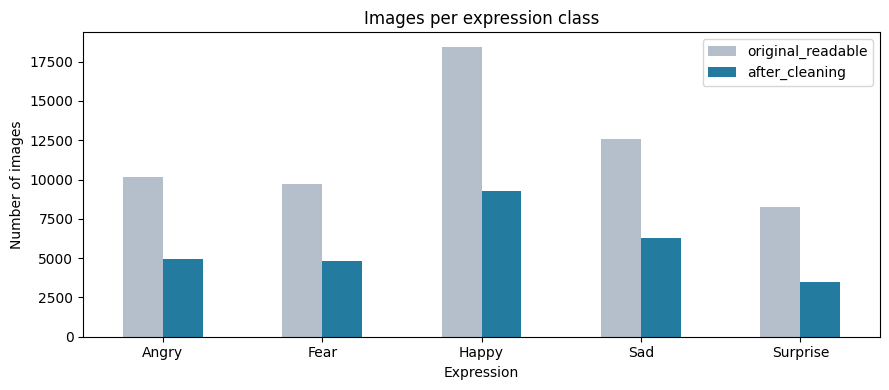

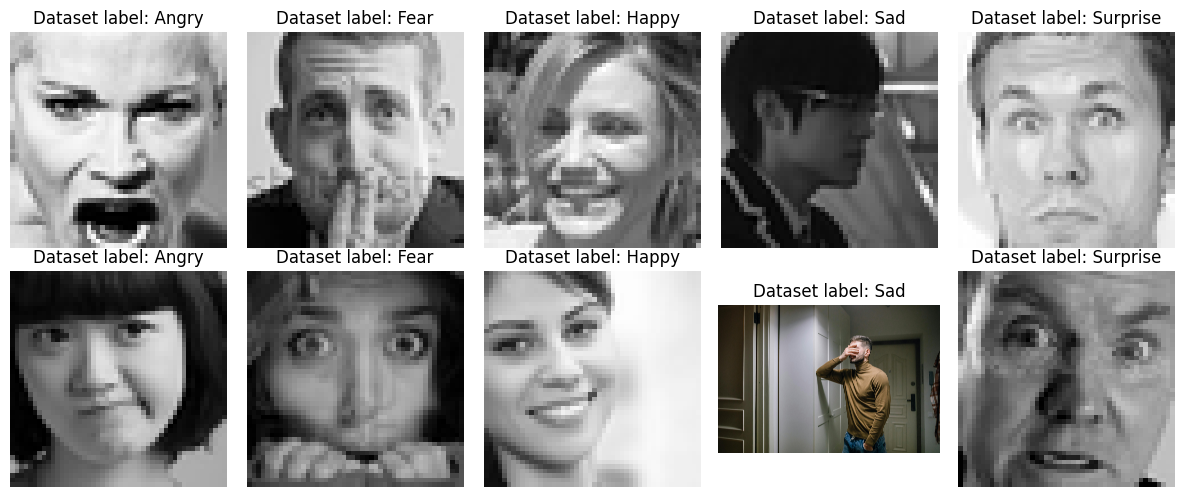

,,image_count
width,height,
48,48,57756
640,640,864
4000,6000,23
150,100,16
6000,4000,16
1600,1067,12
150,225,7
4480,6720,7
6720,4480,7


In [9]:
counts.plot(kind='bar', figsize=(9, 4), color=['#b5becb', '#247ba0'])
plt.title('Images per expression class')
plt.xlabel('Expression')
plt.ylabel('Number of images')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(RUN_DIR / 'class_distribution.png', dpi=150)
plt.show()

fig, axes = plt.subplots(2, len(CLASS_NAMES), figsize=(12, 5))
for column, label in enumerate(CLASS_NAMES):
    examples = clean[clean.label == label].sample(2, random_state=SEED)
    for row, (_, item) in enumerate(examples.iterrows()):
        with Image.open(DATA_DIR / item.path) as image:
            axes[row, column].imshow(ImageOps.exif_transpose(image).convert('RGB'))
        axes[row, column].set_title(f'Dataset label: {label}')
        axes[row, column].axis('off')
plt.tight_layout()
plt.show()
display(manifest.groupby(['width', 'height']).size().sort_values(ascending=False).head(10).rename('image_count'))

In [10]:
train_df, remaining_df = train_test_split(clean, test_size=0.30, stratify=clean.target, random_state=SEED)
val_df, test_df = train_test_split(remaining_df, test_size=0.50, stratify=remaining_df.target, random_state=SEED)
train_df, val_df, test_df = (frame.reset_index(drop=True) for frame in (train_df, val_df, test_df))

split_manifest = pd.concat([train_df.assign(split='train'), val_df.assign(split='validation'),
                            test_df.assign(split='test')], ignore_index=True)
assert split_manifest.path.is_unique
assert split_manifest.pixel_sha256.is_unique
assert len(split_manifest) == len(clean)
assert set(train_df.target) == set(val_df.target) == set(test_df.target) == set(range(len(CLASS_NAMES)))
split_manifest.to_csv(RUN_DIR / 'split_manifest.csv', index=False)
display(pd.crosstab(split_manifest.label, split_manifest.split).reindex(CLASS_NAMES)[['train', 'validation', 'test']])
print('No exact decoded-pixel duplicates cross the splits.')

split,train,validation,test
label,,,
Angry,3471,744,744
Fear,3375,723,724
Happy,6478,1389,1388
Sad,4417,946,947
Surprise,2431,521,520


No exact decoded-pixel duplicates cross the splits.


In [11]:
train_steps = [transforms.Grayscale(num_output_channels=1), transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))]
if USE_AUGMENTATION:
    train_steps.append(transforms.RandomHorizontalFlip(p=0.5))
train_steps += [transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))]
train_transform = transforms.Compose(train_steps)
eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1), transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))
])

class FaceDataset(Dataset):
    def __init__(self, frame, root, transform):
        self.frame = frame.reset_index(drop=True)
        self.root, self.transform = Path(root), transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        item = self.frame.iloc[index]
        with Image.open(self.root / item.path) as image:
            image = ImageOps.exif_transpose(image).convert('RGB')
            tensor = self.transform(image)
        return tensor, int(item.target)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    random.seed(worker_seed)
    np.random.seed(worker_seed)

def make_loaders():
    generator = torch.Generator().manual_seed(SEED)
    options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda',
                   worker_init_fn=seed_worker)
    train_loader = DataLoader(FaceDataset(train_df, DATA_DIR, train_transform), shuffle=True,
                              generator=generator, **options)
    val_loader = DataLoader(FaceDataset(val_df, DATA_DIR, eval_transform), shuffle=False, **options)
    test_loader = DataLoader(FaceDataset(test_df, DATA_DIR, eval_transform), shuffle=False, **options)
    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = make_loaders()
images, labels = next(iter(train_loader))
print('Image batch:', tuple(images.shape), '= (batch, channel, height, width)')
print('Label batch:', tuple(labels.shape))
print('Pixel range:', images.min().item(), images.max().item())

Image batch: (64, 1, 64, 64) = (batch, channel, height, width)
Label batch: (64,)
Pixel range: -1.0 1.0


In [12]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4, 4)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(128 * 4 * 4, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = SimpleCNN(len(CLASS_NAMES)).to(DEVICE)
with torch.no_grad():
    sample_logits = model(images[:2].to(DEVICE))
assert sample_logits.shape == (2, len(CLASS_NAMES))
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))
print('Output for 2 images:', tuple(sample_logits.shape))

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=5, bias=True)
  )
)
Trainable parameters: 355589
Output for 2 images: (2, 5)


In [13]:
train_counts = np.bincount(train_df.target.to_numpy(), minlength=len(CLASS_NAMES))
weights = len(train_df) / (len(CLASS_NAMES) * train_counts)
class_weights = torch.tensor(weights, dtype=torch.float32, device=DEVICE) if USE_CLASS_WEIGHTS else None
criterion = nn.CrossEntropyLoss(weight=class_weights)
display(pd.DataFrame({'class': CLASS_NAMES, 'train_count': train_counts,
                      'loss_weight': weights if USE_CLASS_WEIGHTS else np.ones(len(CLASS_NAMES))}))

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum, loss_denominator = 0.0, 0.0
    all_targets, all_predictions = [], []
    for images, targets in tqdm(loader, desc='Train' if training else 'Evaluate', leave=False):
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, targets)
            if training:
                loss.backward()
                optimizer.step()
        # CrossEntropyLoss(weight=...) divides by the sum of the observed class weights.
        denominator = criterion.weight[targets].sum().item() if criterion.weight is not None else targets.numel()
        loss_sum += loss.item() * denominator
        loss_denominator += denominator
        all_targets.extend(targets.detach().cpu().tolist())
        all_predictions.extend(logits.detach().argmax(dim=1).cpu().tolist())
    metrics = {
        'loss': loss_sum / loss_denominator,
        'accuracy': accuracy_score(all_targets, all_predictions),
        'macro_f1': f1_score(all_targets, all_predictions, labels=list(range(len(CLASS_NAMES))),
                             average='macro', zero_division=0),
    }
    return metrics, np.asarray(all_targets), np.asarray(all_predictions)

,class,train_count,loss_weight
0,Angry,3471,1.162316
1,Fear,3375,1.195378
2,Happy,6478,0.622785
3,Sad,4417,0.913380
4,Surprise,2431,1.659564


In [14]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
train_loader, val_loader, test_loader = make_loaders()
model = SimpleCNN(len(CLASS_NAMES)).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
best_val_f1, best_epoch, stale_epochs = -1.0, 0, 0
history = []
checkpoint_path = RUN_DIR / 'best_model.pt'

for epoch in range(1, EPOCHS + 1):
    started = time.perf_counter()
    train_metrics, _, _ = run_epoch(model, train_loader, criterion, optimizer)
    val_metrics, _, _ = run_epoch(model, val_loader, criterion)
    history.append({'epoch': epoch, **{f'train_{k}': v for k, v in train_metrics.items()},
                    **{f'val_{k}': v for k, v in val_metrics.items()},
                    'seconds': time.perf_counter() - started})
    pd.DataFrame(history).to_csv(RUN_DIR / 'history.csv', index=False)
    print(f"Epoch {epoch}/{EPOCHS} | train loss {train_metrics['loss']:.4f} | "
          f"val loss {val_metrics['loss']:.4f} | val accuracy {val_metrics['accuracy']:.4f} | "
          f"val macro-F1 {val_metrics['macro_f1']:.4f}")
    if val_metrics['macro_f1'] > best_val_f1:
        best_val_f1, best_epoch, stale_epochs = val_metrics['macro_f1'], epoch, 0
        torch.save({'model_state_dict': {k: v.detach().cpu() for k, v in model.state_dict().items()},
                    'class_names': CLASS_NAMES, 'image_size': IMAGE_SIZE,
                    'best_epoch': best_epoch, 'validation_macro_f1': float(best_val_f1),
                    'config': config}, checkpoint_path)
        print('  Saved new best model.')
    else:
        stale_epochs += 1
        if stale_epochs >= PATIENCE:
            print('Early stopping: validation macro-F1 did not improve.')
            break
print(f'Best epoch: {best_epoch}; validation macro-F1: {best_val_f1:.4f}')

Train:   0%|          | 0/316 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/68 [00:00<?, ?it/s]

Epoch 1/5 | train loss 1.5282 | val loss 1.4467 | val accuracy 0.4080 | val macro-F1 0.3549
  Saved new best model.


Train:   0%|          | 0/316 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7effda2a93a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7effda2a93a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

...

Evaluate:   0%|          | 0/68 [00:00<?, ?it/s]

Epoch 4/5 | train loss 1.2129 | val loss 1.2023 | val accuracy 0.5020 | val macro-F1 0.4594
  Saved new best model.


Train:   0%|          | 0/316 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/68 [00:00<?, ?it/s]

Epoch 5/5 | train loss 1.1668 | val loss 1.1513 | val accuracy 0.5434 | val macro-F1 0.5069
  Saved new best model.
Best epoch: 5; validation macro-F1: 0.5069


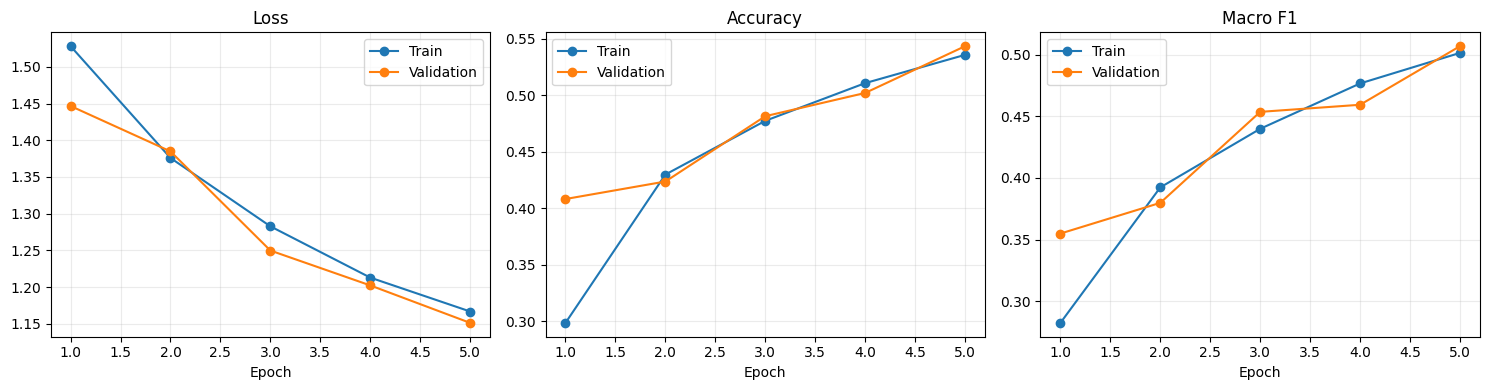

,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,seconds
0,1,1.528198,0.298384,0.282432,1.446685,0.408050,0.354906,109.383123
1,2,1.375944,0.429705,0.392374,1.384850,0.423548,0.379833,102.302772
2,3,1.282810,0.477295,0.439893,1.249818,0.481379,0.453637,120.439092
3,4,1.212949,0.510658,0.476698,1.202313,0.501966,0.459393,100.951542
4,5,1.166782,0.535693,0.501488,1.151279,0.543373,0.506935,128.573429


In [15]:
history_df = pd.read_csv(RUN_DIR / 'history.csv')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, metric in zip(axes, ['loss', 'accuracy', 'macro_f1']):
    axis.plot(history_df.epoch, history_df[f'train_{metric}'], marker='o', label='Train')
    axis.plot(history_df.epoch, history_df[f'val_{metric}'], marker='o', label='Validation')
    axis.set(title=metric.replace('_', ' ').title(), xlabel='Epoch')
    axis.legend()
    axis.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(RUN_DIR / 'training_curves.png', dpi=150)
plt.show()
display(history_df)

Evaluate:   0%|          | 0/68 [00:00<?, ?it/s]

{
  "loss": 1.1241835691172852,
  "accuracy": 0.5641915336571826,
  "macro_f1": 0.5331412357793086,
  "best_epoch": 5,
  "best_validation_macro_f1": 0.506934725304087,
  "test_samples": 4323
}


,precision,recall,f1-score,support
Angry,0.533835,0.381720,0.445141,744.000000
Fear,0.331092,0.272099,0.298711,724.000000
Happy,0.793750,0.731988,0.761619,1388.000000
Sad,0.439486,0.613516,0.512120,947.000000
Surprise,0.607744,0.694231,0.648115,520.000000
accuracy,0.564192,0.564192,0.564192,0.564192
macro avg,0.541181,0.538711,0.533141,4323.000000
weighted avg,0.571554,0.564192,0.561318,4323.000000


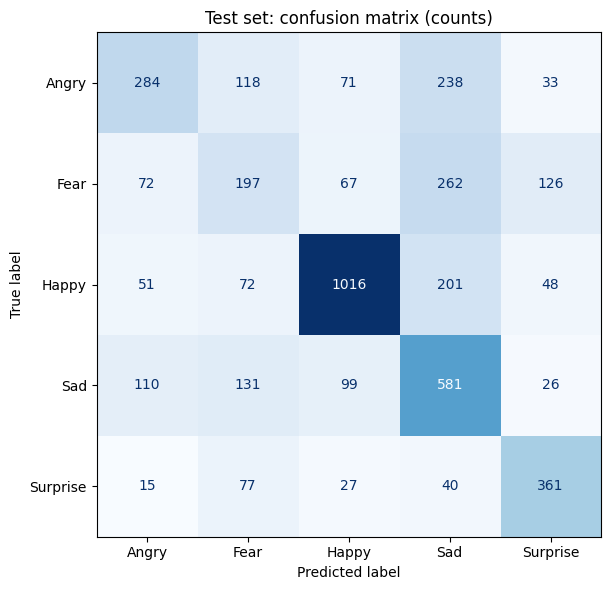

In [16]:
checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
test_metrics, y_true, y_pred = run_epoch(model, test_loader, criterion)
class_ids = list(range(len(CLASS_NAMES)))
report = classification_report(y_true, y_pred, labels=class_ids, target_names=CLASS_NAMES,
                               output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).transpose()
report_df.to_csv(RUN_DIR / 'classification_report.csv')
test_results = {**test_metrics, 'best_epoch': checkpoint['best_epoch'],
                'best_validation_macro_f1': checkpoint['validation_macro_f1'], 'test_samples': len(test_df)}
(RUN_DIR / 'test_metrics.json').write_text(json.dumps(test_results, indent=2))
print(json.dumps(test_results, indent=2))
display(report_df)

predictions = test_df[['path', 'label', 'target']].copy()
predictions['predicted_index'] = y_pred
predictions['predicted_label'] = [CLASS_NAMES[index] for index in y_pred]
predictions.to_csv(RUN_DIR / 'test_predictions.csv', index=False)
cm = confusion_matrix(y_true, y_pred, labels=class_ids)
pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(RUN_DIR / 'confusion_matrix.csv')
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Test set: confusion matrix (counts)')
plt.tight_layout()
plt.savefig(RUN_DIR / 'confusion_matrix.png', dpi=150)
plt.show()

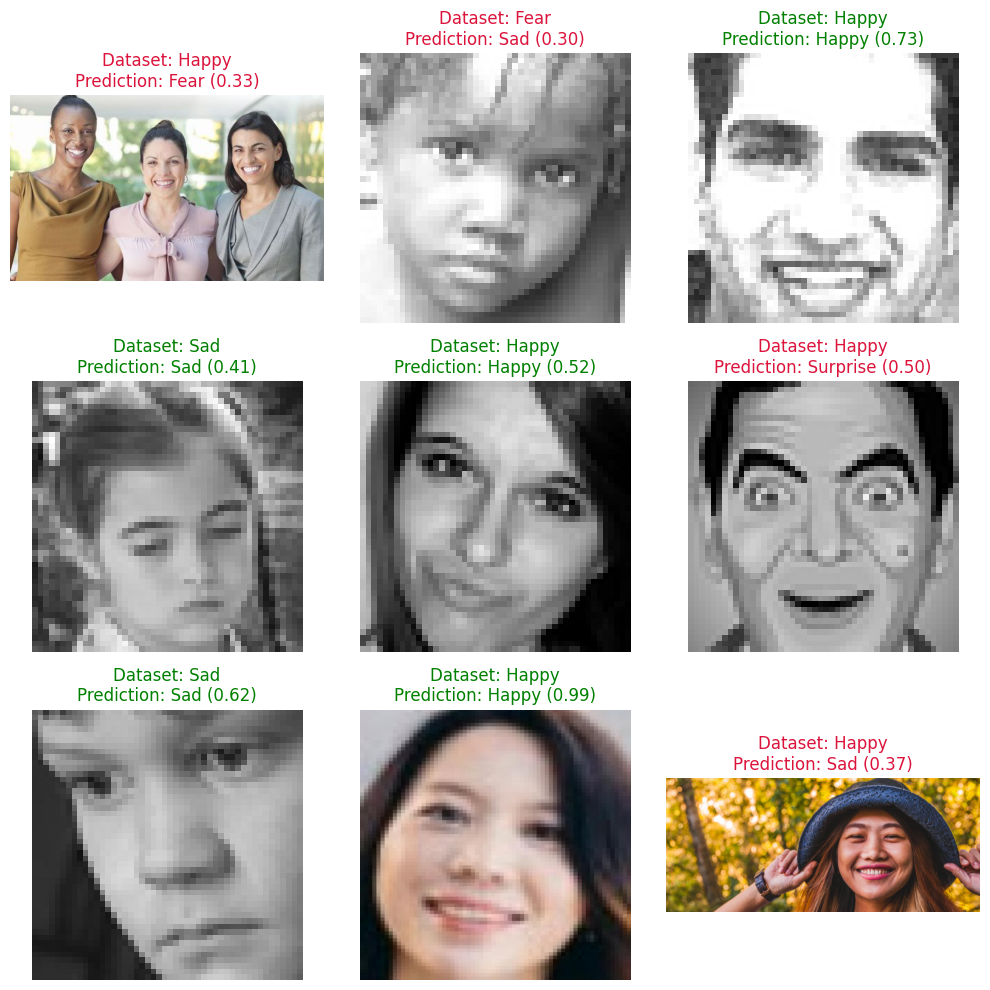

In [17]:
@torch.inference_mode()
def predict_image(path):
    model.eval()
    with Image.open(path) as image:
        rgb = ImageOps.exif_transpose(image).convert('RGB')
        tensor = eval_transform(rgb).unsqueeze(0).to(DEVICE)
    scores = torch.softmax(model(tensor), dim=1).squeeze(0).cpu().numpy()
    return CLASS_NAMES[int(scores.argmax())], {name: float(score) for name, score in zip(CLASS_NAMES, scores)}

examples = test_df.sample(n=min(9, len(test_df)), random_state=SEED)
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for axis in axes.flat:
    axis.axis('off')
for axis, (_, item) in zip(axes.flat, examples.iterrows()):
    path = DATA_DIR / item.path
    predicted_label, scores = predict_image(path)
    with Image.open(path) as image:
        axis.imshow(ImageOps.exif_transpose(image).convert('RGB'))
    axis.set_title(f'Dataset: {item.label}\nPrediction: {predicted_label} ({scores[predicted_label]:.2f})',
                   color='green' if predicted_label == item.label else 'crimson')
plt.tight_layout()
plt.savefig(RUN_DIR / 'sample_predictions.png', dpi=150)
plt.show()

In [18]:
experiment_log = pd.DataFrame([{
    'run': RUN_DIR.name, 'seed': SEED, 'image_size': IMAGE_SIZE, 'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE, 'epochs_completed': len(history), 'best_epoch': checkpoint['best_epoch'],
    'augmentation': USE_AUGMENTATION, 'class_weights': USE_CLASS_WEIGHTS,
    'validation_macro_f1': checkpoint['validation_macro_f1'],
    'test_accuracy': test_metrics['accuracy'], 'test_macro_f1': test_metrics['macro_f1'],
    'notes': 'First CNN baseline; add your observations here.'
}])
experiment_log.to_csv(RUN_DIR / 'experiment_log.csv', index=False)
display(experiment_log)
print('Saved outputs:')
for path in sorted(RUN_DIR.iterdir()):
    print(f'  {path.name} ({path.stat().st_size / 1024:.1f} KB)')
print('Persistent Google Drive folder:', RUN_DIR)

,run,seed,image_size,batch_size,learning_rate,epochs_completed,best_epoch,augmentation,class_weights,validation_macro_f1,test_accuracy,test_macro_f1,notes
0,20261016_032542_645127_UTC,42,64,64,0.001,5,5,True,True,0.506935,0.564192,0.533141,First CNN baseline; add your observations here.


Saved outputs:
  audit_manifest.csv (5926.9 KB)
  audit_summary.json (0.2 KB)
  best_model.pt (1393.6 KB)
  class_distribution.png (42.9 KB)
  classification_report.csv (0.6 KB)
  clean_manifest.csv (2941.6 KB)
  config.json (0.6 KB)
  conflicting_labels.csv (26.5 KB)
  confusion_matrix.csv (0.1 KB)
  confusion_matrix.png (53.0 KB)
  environment_versions.json (0.2 KB)
  experiment_log.csv (0.3 KB)
  history.csv (0.7 KB)
  invalid_images.csv (0.0 KB)
  sample_predictions.png (707.0 KB)
  split_manifest.csv (3127.3 KB)
  test_metrics.json (0.2 KB)
  test_predictions.csv (140.9 KB)
  training_curves.png (105.1 KB)
Persistent Google Drive folder: /content/drive/MyDrive/fer_cnn_outputs/20261016_032542_645127_UTC


In [20]:
DOWNLOAD_RESULTS = True  # Change to True if you want a download.
if DOWNLOAD_RESULTS:
    from google.colab import files
    results_zip = shutil.make_archive(f'/content/{RUN_DIR.name}_results', 'zip', root_dir=RUN_DIR)
    files.download(results_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
!git --version

git version 2.43.0


In [22]:
!git status

fatal: not a git repository (or any of the parent directories): .git


In [24]:
!pwd
!ls

/content
20261016_032542_645127_UTC_results.zip	drive  fer_data  sample_data


In [25]:
!git clone https://github.com/salmakamila126/facial-expression-recognition-cnn-pytorch.git

Cloning into 'facial-expression-recognition-cnn-pytorch'...


In [26]:
%cd /content/facial-expression-recognition-cnn-pytorch

/content/facial-expression-recognition-cnn-pytorch


In [27]:
!git status
!git branch

On branch main

No commits yet

nothing to commit (create/copy files and use "git add" to track)


In [38]:
!git commit -m "Initial commit: project setup"

On branch main
Your branch is based on 'origin/main', but the upstream is gone.
  (use "git branch --unset-upstream" to fixup)

nothing to commit, working tree clean


In [39]:
!git switch -c salma

Switched to a new branch 'salma'


In [40]:
!git branch

  main
* salma


In [41]:
!find /content/drive/MyDrive -name "CNN.ipynb"

/content/drive/MyDrive/Colab Notebooks/CNN.ipynb
